# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
print(plans.head(5))

  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [4]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
print(plans.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
None


In [8]:
print(users.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB
None


In [9]:
print(usage.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB
None


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
 
**Comentarios preliminares:**
- Dataset plans: Funciona únicamente como una tabla de referencia (catálogo) de los productos disponibles.
- Columna city: Presenta un 11 % de valores nulos respecto al total de registros (4,000). Al ser una columna categorica no representa problemas criticos con relacion a las metricas comunes, se imputarán estos valores como 'desconocido' para mantener la integridad y conservar la totalidad de los datos. Se recomienda revisar el manejo de esta columna ya que es un importante valor de rango categorico, el porcentaje de nulos es bastante alto para un dato de gran relevancia para metricas especificas.
- Columna churn_date: Se conserva la columna a pesar del 88 % de valores NaN encontrados, ya que puede contener información útil para el análisis (promedios, identificación de usuarios activos, rango de fechas de cancelación, etc.).
- Columnas duration y length: Muestran un 55 % y un 45 % de valores nulos, respectivamente. Tras una inspección visual, se determinó que son mutuamente excluyentes (responden a distintos tipos de registros o servicios), por lo que se conservarán en su estado original para realizar las métricas y operaciones correspondientes sin alterar su naturaleza.


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

- La columna `user_id` es de varables identificadoras asi que no se trataran para metricas operativas
- La columna `age` no parece tener problemas de valores nulos, aun falta inspeccionar por outliers.

In [12]:
print(usage.select_dtypes(include='number').describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` se consideran variables identificadoras y no incluiran en metricas cuantitativas
- Las columnas 'duration' y 'length' pueden ser directamente complementarias de las columnas 'call' y 'text' ademas de servir para metricas especifcas aun o especialmente por todos los valores nulos que contiene.

In [13]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].value_counts())


city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64


- La columna `city` ademas del alto numero de valores nulos (11 %) se debe agregar otro 0.24 % debido a que existe un valor '?' que tambien aplica como 'desconocido'
- La columna `plan` no parece tener problemas significativos.

# explorar columna categórica de usage

In [14]:
print(usage['type'].value_counts())

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` no parece tener problemas; solo contiene dos variables categoricas sin ningun nan.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- Se encontraron *sentinels* ('?') en la columna 'city', y hay que dar el formato correcto a la columna 'date', ya que ahora se presenta como object, lo cual interfiere con cualquier métrica básica.

- El verdadero problema se presenta en 'city', ya que la elevada cantidad de valores nulos o desconocidos refleja un error importante y grave que debe ser atendido a la brevedad; si bien el proceso para obtener las métricas necesarias para el análisis actual puede verse complicado, es un hecho que el sistema de captura de datos en ese paso tiene una deficiencia.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [15]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [16]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [17]:
# Revisar los años presentes en `reg_date` de users
users_years=(users['reg_date'].dt.year)
users_years.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

- En reg_date, aparecen los años 2024, 2023 y 2022 con datos consistentes con el dataset; sin embargo, se observa una discrepancia al faltar el año 2025 y haber solo unos pocos registros de 2026. Se plantea la posibilidad de que esos datos de 2026 correspondan a un error de captura, por lo que se deja la observación y la sugerencia de revisarlos en su momento.

In [18]:
usage['date'].dtype


dtype('<M8[ns]')

In [19]:
# Revisar los años presentes en `date` de usage
usage_years=usage['date'].dt.year
usage_years.value_counts()

2024.0    39950
Name: date, dtype: int64

- En `date`, solo se encuentran registros del año 2024 lo cual determina que el dataset de actividades (llamadas, mensajes) se limita a un bloque comprendido solo en ese año.
- Se observa una reducida cantidad de valores nulos que no afectan de manera significativa las metricas requeridas. 
- Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
import numpy as np
age_mediana = users['age'].median()
users['age'] = np.where(users['age']== -999,age_mediana,users['age'])


# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city']=np.where(users['city']== '?','NA',users['city'])

# Verificar cambios
users['city'].describe()

count       3531
unique         7
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:
# Marcar fechas futuras como NA para reg_date
users['reg_date']=pd.to_datetime(users['reg_date'], errors= 'coerce', utc=True)
fecha_limite = pd.Timestamp('2024-12-31', tz='UTC')
users['reg_date']=np.where(users['reg_date']>fecha_limite, 'NA', users['reg_date'])

# Verificar cambios
users['reg_date'].describe()

count     4000
unique    3961
top         NA
freq        40
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:

# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).sum()

type
call        0
text    22076
Name: duration, dtype: int64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).sum()

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
- los valores nulos aparecen en su totalidad, con una categoria definida: para `duration` se corresponden con 'text' y para `length` con call.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text','is_call','duration']].agg('sum').reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg=usage_agg.rename(columns={'is_text':'cant_mensajes','is_call':'cant_llamadas', 'duration':'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users,usage_agg, on=['user_id'], how='inner')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['age','cant_mensajes','cant_llamadas','cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.124531,5.524381,4.478120,23.317054
std,17.692032,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

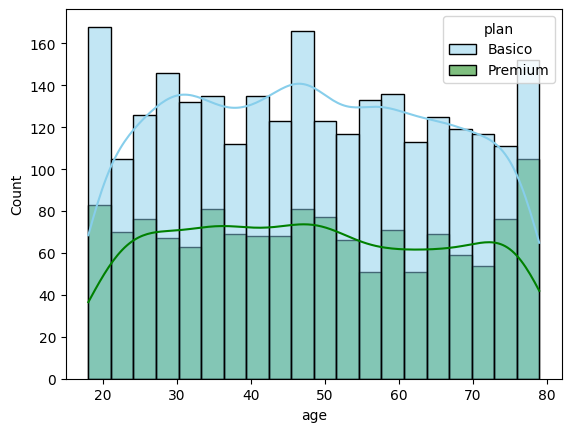

In [30]:
# Histograma para visualizar la edad (age)
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x='age', bins=20, hue='plan', palette=['skyblue','green'], kde=True)
plt.show()

💡Insights: 
-Se observa una distribución un tanto simétrica, sin desviaciones marcadas.

- Si bien el plan básico es evidentemente elegido en mayor escala, se aprecia que todos los rangos de edad adquieren ambos planes en la misma proporción.

- La cantidad de usuarios más alta para el plan básico se observa en los rangos más jóvenes, seguida por usuarios de alrededor de 47 años.

- Caso contrario con el plan premium, que cuenta con un mayor número de usuarios en el rango de entre 75 y 80 años.

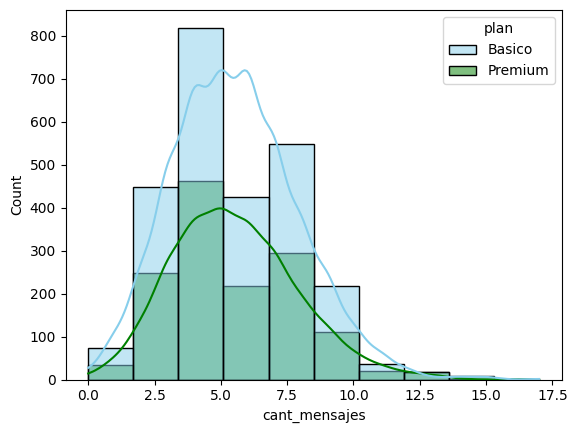

In [31]:
# Histograma para visualizar la cant_mensajes
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x='cant_mensajes', bins=10, hue='plan', palette=['skyblue','green'], kde=True)
plt.show()

💡Insights: 
- Se observa un ligero sesgo a la derecha, no crítico, ya que el rango general de los datos va desde cero hasta 17.5.

- La distribución en general parece coherente y estable, sin valores atípicos evidentes y con un rango de datos bastante manejable.

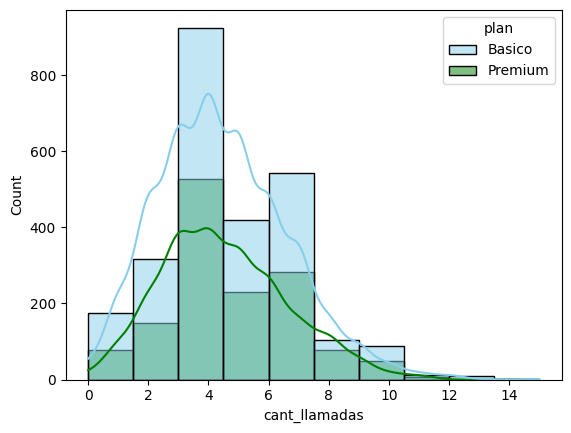

In [32]:
# Histograma para visualizar la cant_llamadas
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x='cant_llamadas', bins=10, hue='plan', palette=['skyblue','green'], kde=True)
plt.show()

💡Insights: 
- Se observa un ligero sesgo a la derecha, no crítico, ya que el rango general de los datos va desde cero hasta 15.

- La distribución en general parece coherente y estable, sin valores atípicos evidentes y con un rango de datos bastante manejable; muy similar a lo visto en 'cant_mensajes' lo cual indica un comparativo coherente del comportamiento de los usuarios.

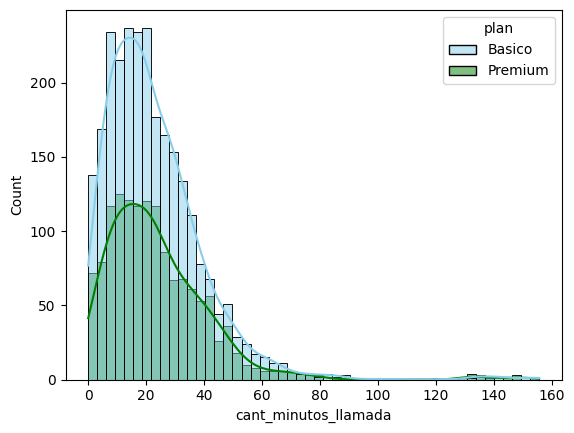

In [33]:
# Histograma para visualizar la cant_minutos_llamada
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x='cant_minutos_llamada', bins=50, hue='plan', palette=['skyblue','green'], kde=True)
plt.show()


💡Insights: 
- Se ve un evidente sesgo a la derecha, lo cual puede interferir con ciertas métricas; se mantendrá la atención en este aspecto.

- Asimismo, se deja manifiesto el comentario de que un gran número de valores caen en el rango de '0 minutos'; sin embargo, se debe considerar que los registros en este rango van desde 0 minutos : 0 segundos (por ejemplo: llamadas realizadas pero canceladas o llamadas que no se conectaron) hasta 0 minutos : 59 segundos (llamadas de menos de un minuto).


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

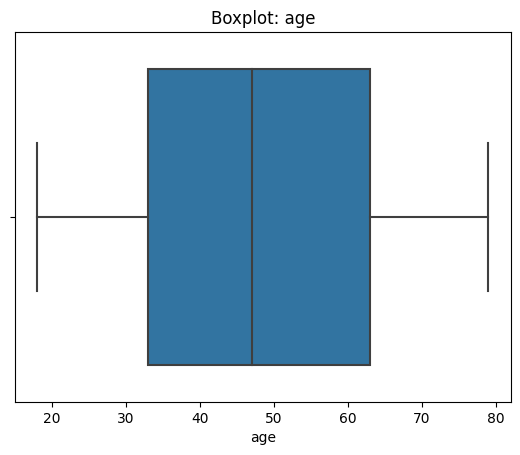

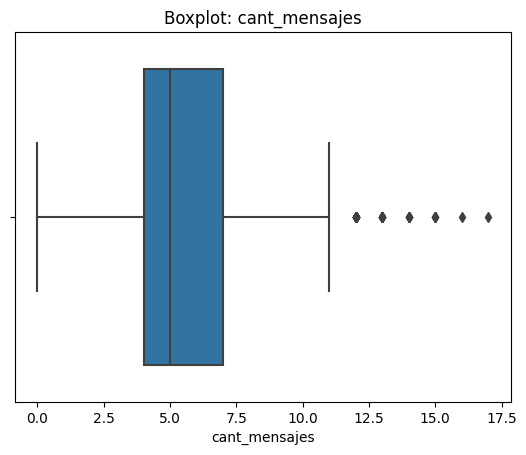

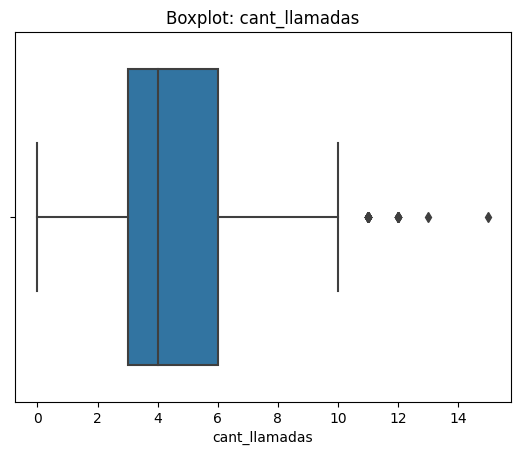

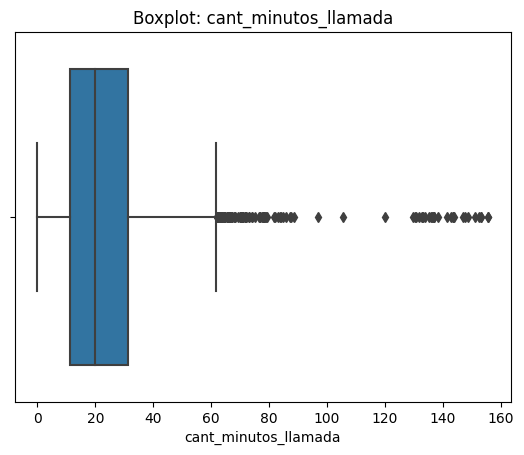

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()
    

💡Insights: 
- Age: no presenta outliers, valores estables en general.
- cant_mensajes: se aprecian algunos outliers facilmente localizables e imputables de ser necesario.
- cant_llamadas: como ya se ha hecho mencion en el anlisis de histograma, los valores son estables y coherentes, similares a la columna 'cant_mensajes', se procedera con tratamientos pertinentes.
- cant_minutos_llamada: es este caso se observan un elevado numero de outliers, se recomienda especial atencion empezando por un analisis directo con ayuda del metodo de cuantiles.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    print(col)
    q1= user_profile[col].quantile (0.25)
    q3= user_profile[col].quantile (0.75)
    iqr= q3 - q1
    print('IQR:',iqr)
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    print('limite inferior:', lower)
    print('limite superior:', upper)
    print('outliers_abajo:', len(user_profile[user_profile [col] < lower]))
    print('outliers_arriba:', len(user_profile[user_profile [col] > upper ]))
    print('='*80)
    print('\n\n')
    



age
IQR: 30.0
limite inferior: -12.0
limite superior: 108.0
outliers_abajo: 0
outliers_arriba: 0



cant_mensajes
IQR: 3.0
limite inferior: -0.5
limite superior: 11.5
outliers_abajo: 0
outliers_arriba: 46



cant_llamadas
IQR: 3.0
limite inferior: -1.5
limite superior: 10.5
outliers_abajo: 0
outliers_arriba: 30



cant_minutos_llamada
IQR: 20.295
limite inferior: -19.322500000000005
limite superior: 61.8575
outliers_abajo: 0
outliers_arriba: 109





In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.124531,5.524381,4.478120,23.317054
std,17.692032,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


#💡Insights: 
##- cant_mensajes: mantener o no outliers, porqué?
- Se mantendrán los outliers al ser apenas un porcentaje muy bajo sin probabilidad de influir de forma indebida en las métricas por calcular.
##- cant_llamadas: mantener o no outliers, porqué?
- Para cant_llamadas se da el mismo caso que en cant_mensajes, al ser apenas 30 valores de 4,000 los que se encuentran por encima del límite superior; además, el valor máximo (15) está apenas 5 unidades por arriba del límite superior.
##- cant_minutos_llamada: mantener o no outliers, porqué?
- Aunque el boxplot realizado para esta columna parecía contener un elevado número de valores outliers, se encontró que solo se trataba de un porcentaje mínimo (109 de 4000 para un 2.72 %); cabe mencionar que, si bien el valor máximo se encuentra unas 100 unidades fuera del límite superior (155 frente a 61), es perfectamente posible.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
import numpy as np
user_profile['grupo_uso']= np.where((user_profile['cant_llamadas']<5) & (user_profile['cant_mensajes']<5), 'Bajo uso', 
np.where((user_profile['cant_llamadas']<10) & (user_profile['cant_mensajes']<10), 'Uso medio', 'Alto uso'))

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where ((user_profile['age']< 30), 'Joven',
                             np.where ((user_profile['age']< 60), 'Adulto', 'Adulto mayor'))

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11,3,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4,3,8.01,Bajo uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

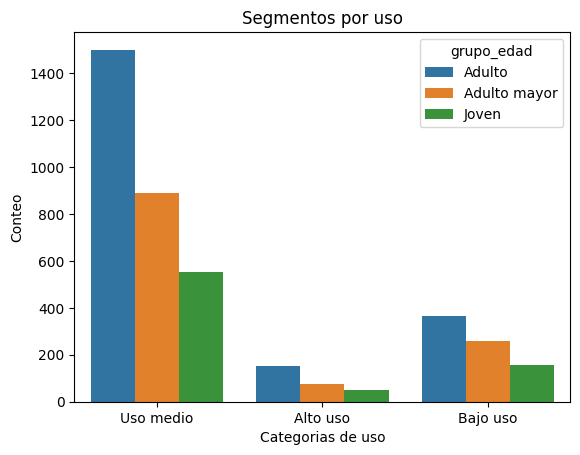

In [52]:
# Visualización de los segmentos por uso
sns.countplot(x='grupo_uso', data=user_profile, hue='grupo_edad')
plt.title('Segmentos por uso')
plt.xlabel('Categorias de uso')
plt.ylabel('Conteo')
plt.show()

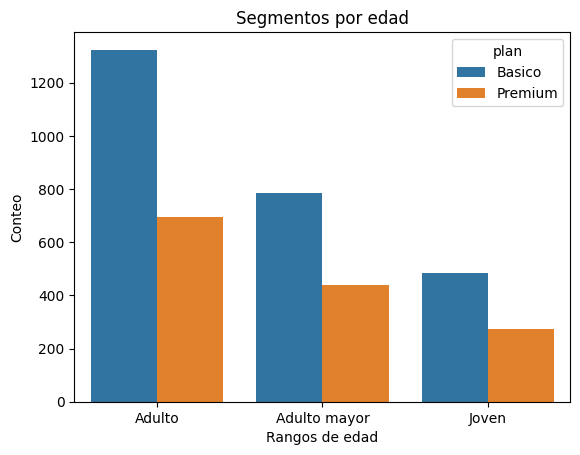

In [44]:
# Visualización de los segmentos por edad
# Visualización de los segmentos por uso
sns.countplot(x='grupo_edad', data=user_profile, hue='plan')
plt.title('Segmentos por edad')
plt.xlabel('Rangos de edad')
plt.ylabel('Conteo')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- df_plans: dataframe categorico, catalogo de referencia, sin mayores problemas.
  
- df_users: 'age', sin problemas evidentes o criticos, valores estables y coherentes;	| 'city', se encontro un 11 % de nulos, no hubo metricas afectadas por dicha situacion; |	'reg_date', sin detalles criticos; |	'plan', variables categoricas, sin problemas criticos; | 'churn_date', se observaron alto porcentaje de nulos (88 %) cuyo origen se determino como correspondiente a usuarios activos, no interfiere con metricas solicitadas.

- df_usage: 'type', dos variables categoricas sin mayor problema;	| 'date', valores definidos coherentemente, sin problemas; |	'duration' y 'length', se encuentra relacion directa de nulos entre ambas columnas (55 % y 45 %), tienen correspondencia directa con columna 'type' valores text y call respectivamente.

🔍 **Segmentos por Edad**
- Usuarios comprendidos en el segmento 'adulto' tienen las sumatorias mas altas en consumo para ambos planes (Basico y Premium)
- El consumo en ambos planes es proporcional entre los diversos segmentos, lo cual podria deberse a un marketing continuo y bien focalizado.

📊 **Segmentos por Nivel de Uso**
- Los segmentos 'Adulto' y 'Adulto mayor'siguen manteniendo las metricas mas altas.
- Aunque se debe principalmente a una estadistica relativamente baja en el segmento 'Alto uso'


➡️ El marketing debiera enfocarse en aumentar las estadisticas para 'Alto uso' en ambos planes.

💡 **Recomendaciones**
- La captura de datos en 'city' se encuentra comprometida lo que se refleja en el alto numero de valores nulos ya documentados.
- El marketing en terminos genrales parece ser constante pero se sugiere aprovechar las bajas sumatorias en el segmento 'Alto uso' para implementar estrategias comerciales sobre ese sector, de minimo se debiera intentar mover algunos usuarios de uso medio a  alto.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`